In [13]:
import sys
sys.path.append('../')

import pandas as pd
import numpy as np
import json
from sqlalchemy import text
from src.db_connect import get_engine
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Create engine
engine = get_engine()

In [14]:
df_customers = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.prep_customer_metrics;'), con=engine)
df_customers_insights = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_customer_insights;'), con=engine)
df_sessions = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.prep_session_conversion;'), con=engine)
df_transactions = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.stg_transaction_metadata;'), con=engine)


In [16]:
# 1.lifecycle_stage column based on conditions
df_customers_insights['lifecycle_stage'] = 'Unknown'

mask_new = (df_customers_insights['frequency'] <= 2) & (df_customers_insights['recency_days'] <= 30)
df_customers_insights.loc[mask_new, 'lifecycle_stage'] = 'New Customer'

mask_active = (df_customers_insights['frequency'] > 2) & (df_customers_insights['recency_days'] <= 30)
df_customers_insights.loc[mask_active, 'lifecycle_stage'] = 'Active Customer'

mask_dormant = df_customers_insights['recency_days'] > 180
df_customers_insights.loc[mask_dormant, 'lifecycle_stage'] = 'Dormant Customer'

mask_at_risk = (df_customers_insights['frequency'] > 2) & (df_customers_insights['recency_days'].between(31, 180))
df_customers_insights.loc[mask_at_risk, 'lifecycle_stage'] = 'At Risk Customer'


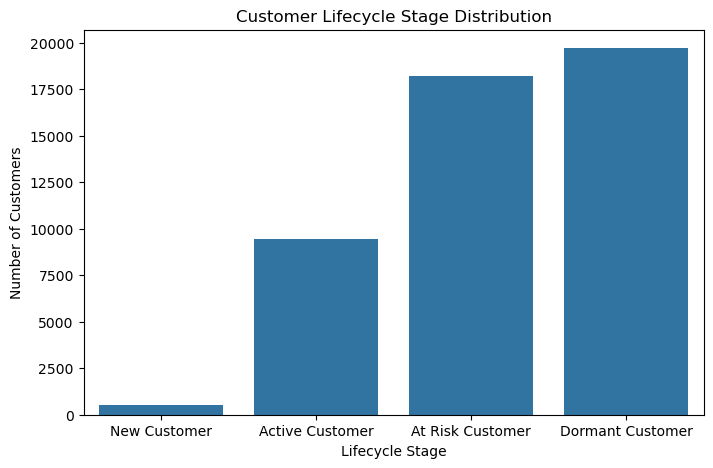

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=df_customers_insights, x='lifecycle_stage', order=['New Customer', 'Active Customer', 'At Risk Customer', 'Dormant Customer'])
plt.title('Customer Lifecycle Stage Distribution')
plt.xlabel('Lifecycle Stage')
plt.ylabel('Number of Customers')
plt.show()

spending differs by customer lifecycle.

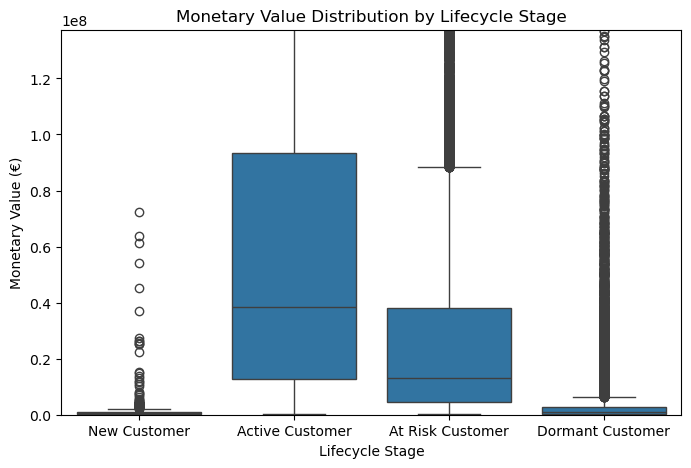

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_customers_insights, x='lifecycle_stage', y='monetary', order=['New Customer', 'Active Customer', 'At Risk Customer', 'Dormant Customer'])
plt.title('Monetary Value Distribution by Lifecycle Stage')
plt.xlabel('Lifecycle Stage')
plt.ylabel('Monetary Value (€)')
plt.ylim(0, df_customers_insights['monetary'].quantile(0.95))  # limit y-axis to 95th percentile for better visualization
plt.show()

In [3]:
# Select only the demographic columns we want to add from df_customers
demographics_to_add = df_customers[['customer_id','first_purchase_date', 'last_purchase_date' ]].copy()

# Merge the RFM insights with these selected customer demographics
# We use a 'left' merge to keep all customers from the insights table
merged_customer_data = pd.merge(
    df_customers_insights,
    demographics_to_add,
    on='customer_id',
    how='left'
)
merged_customer_data.head()

,customer_id,full_name,email,gender,device_type,home_location,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_total,customer_segment,churn_flag,activity_status,first_purchase_date,last_purchase_date
0,100,Gilda Nurdiyanti,ed22ddc5_151b_4128_9590_de9b0bc8bfc6@startupca...,Female,Android,Jawa Timur,1088,2,227544.0,1,1,1,3,At Risk Customer,1,Churned,2016-08-15,2019-08-08
1,10000,Cakrabuana Ardianto,818ffe25_3914_4386_9449_d693a05264f1@zakyfound...,Male,Android,Jawa Tengah,44,8,7178324.0,2,2,2,6,Loyal Customer,0,Active,2021-07-22,2022-06-17
2,10001,Ella Suryatmi,8ae0c4fa_171a_466f_9863_64cbb22f956e@startupca...,Female,Android,Banten,81,11,10574864.0,2,2,2,6,Loyal Customer,0,Active,2019-10-29,2022-05-11
3,10002,Labuh Santoso,2ca61485_e5f8_43f8_8000_df57c3d5da27@startupca...,Male,iOS,Jawa Tengah,220,3,918279.0,1,1,1,3,At Risk Customer,1,Churned,2020-10-05,2021-12-23
4,10003,Makara Sitompul,13fc2a1c_0582_4268_81f1_d8f6e4511904@startupca...,Male,Android,Jawa Tengah,198,3,801299.0,1,1,1,3,At Risk Customer,1,Churned,2020-12-04,2022-01-14


In [4]:
# 1. Convert date column and define reference point
merged_customer_data['last_purchase_date'] = pd.to_datetime(merged_customer_data['last_purchase_date'])
today = pd.to_datetime("2022-07-31")  # Reference date based on your data


In [5]:
# 2. Calculate recency and churn flag
merged_customer_data['recency_days'] = (today - merged_customer_data['last_purchase_date']).dt.days
merged_customer_data['churn_flag'] = merged_customer_data['recency_days'].apply(lambda x: 1 if x > 90 else 0)


In [7]:
# 3. Churn rate by customer segment
churn_rate = merged_customer_data.groupby('customer_segment')['churn_flag'].mean().reset_index()
churn_rate.columns = ['Customer Segment', 'Churn Rate']
churn_rate['Churn Rate'] = churn_rate['Churn Rate'] * 100  # Convert to percentage


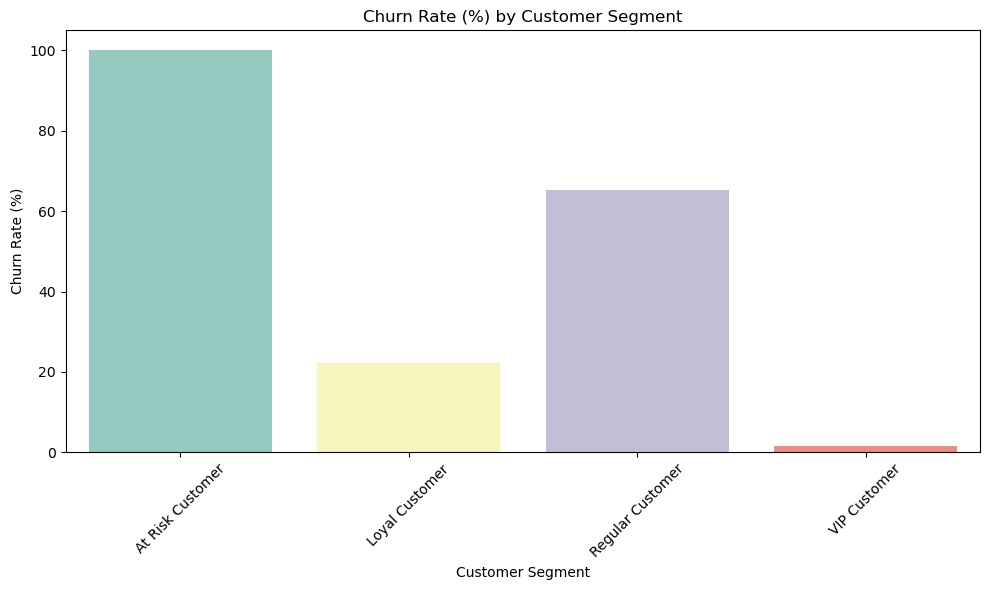

In [8]:
# 4. Plot churn rate
plt.figure(figsize=(10, 6))
sns.barplot(
    data=churn_rate,
    x='Customer Segment',
    y='Churn Rate',
    hue='Customer Segment',
    palette='Set3',
    dodge=False,
    legend=False
)
plt.title('Churn Rate (%) by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Count of total and churned customers per segment
check_counts = merged_customer_data.groupby('customer_segment')['churn_flag'].agg(['count', 'sum'])
check_counts.columns = ['Total Customers', 'Churned Customers']
check_counts['Churn Rate (%)'] = (check_counts['Churned Customers'] / check_counts['Total Customers']) * 100
check_counts['Churn Rate (%)'] = check_counts['Churn Rate (%)'].map(lambda x: f"{x:.2f}".rstrip('0').rstrip('.') + '%')

print(check_counts)

                  Total Customers  Churned Customers Churn Rate (%)
customer_segment                                                   
At Risk Customer            17613              17613           100%
Loyal Customer               8768               1950         22.24%
Regular Customer            12025               7837         65.17%
VIP Customer                11836                186          1.57%


In [11]:
merged_customer_data[['customer_segment', 'last_purchase_date', 'recency_days', 'churn_flag']].sample(10)


,customer_segment,last_purchase_date,recency_days,churn_flag
27792,Regular Customer,2022-02-15,166,1
6919,Regular Customer,2022-02-14,167,1
15879,At Risk Customer,2016-10-19,2111,1
24336,At Risk Customer,2022-01-30,182,1
41062,Loyal Customer,2022-05-08,84,0
48549,At Risk Customer,2021-12-31,212,1
11083,VIP Customer,2022-07-19,12,0
21804,VIP Customer,2022-07-09,22,0
42472,VIP Customer,2022-06-21,40,0
160,At Risk Customer,2021-03-20,498,1


In [12]:
print(merged_customer_data['last_purchase_date'].isnull().sum())


0


In [13]:
summary = merged_customer_data.groupby('customer_segment').agg({
    'frequency': 'mean',
    'monetary': 'mean',
    'recency_days': 'mean'
}).reset_index()

print(summary)

   customer_segment  frequency      monetary  recency_days
0  At Risk Customer   1.945324  1.010088e+06    671.521944
1    Loyal Customer  13.418910  2.224654e+07     64.121921
2  Regular Customer   5.458046  8.347612e+06    192.692973
3      VIP Customer  50.558550  9.360693e+07     29.224738
